# 10 - Vista plegada en fase y red feedforward (mejora M1)

Dos hallazgos anteriores motivan este experimento:
- la CNN sobre la curva completa detecta caídas pero no su repetición (notebook 08);
- los planetas que se escapan son aquellos en que la repetición no se aprovecha (notebooks 07 y 08).

Siguiendo a Shallue y Vanderburg (2018), se **pliega** cada curva en el período del mejor ajuste BLS: todas las
repeticiones del tránsito caen en la misma fase y, al promediar por intervalos, el ruido baja y el tránsito se vuelve
explícito. Por estrella hay dos vistas centradas en el tránsito: **global** (la órbita completa, 201 valores) y
**local** (±3 duraciones alrededor del tránsito, 61 valores). Código: `src/folding.py` (vistas),
`scripts/compute_folded.py` (cálculo, ~10 min) y `src/models_mlp.py` (red feedforward).

Sobre las vistas se entrena una **red feedforward** (perceptrón multicapa 262 → 64 → 32 → 1, ReLU, dropout 0,3,
pérdida ponderada por clase) y, para comparar, un Random Forest. También se prueban combinadas con las 18 features.
Mismo protocolo que el resto (CV 5×5, seed 0) y diferencias pareadas contra el RF con 18 features. **Se reportan
todas las variantes probadas.**

In [1]:
import sys
sys.path.append('..')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.evaluation import repeated_cv, summarize_cv, choose_threshold, compute_metrics, paired_diff, paired_tests, holm
from src.folding import N_GLOBAL, N_LOCAL
from src.models_classic import make_random_forest, select_columns
from src.models_mlp import FeedforwardClassifier

pd.set_option('display.width', 200)
ACENTO, NEGATIVO, GRIS, TEXTO = '#2a78d6', '#eb6834', '#a3a29d', '#52514e'
OUT, ABL = Path('../results/10_plegado'), Path('../results/07_ablacion')
OUT.mkdir(exist_ok=True)

d = np.load('../results/folded_train.npz')
V, y = d['views'].astype(np.float64), d['label']
F = pd.read_csv('../results/features_train.csv')
cols = select_columns(F, 'todas')
assert (F.label.to_numpy() == y).all()
X18 = F[cols].to_numpy()
print('vistas:', V.shape, '| positivos:', y.sum())

vistas: (5087, 262) | positivos: 37


## Cómo se ven las vistas

Arriba, dos estrellas con planeta. En la 18 (período de 7,6 d) las repeticiones se apilan en un tránsito nítido. En la
28 (período de ~30 d) la vista global apenas lo muestra: solo hay dos pasos por la órbita. Abajo, la vista promedio
de las estrellas con y sin planeta, en la misma escala: **las estrellas sin planeta también muestran una caída en el
centro**, porque el BLS siempre centra la vista en la "mejor caída" que encuentra, aunque sea ruido.

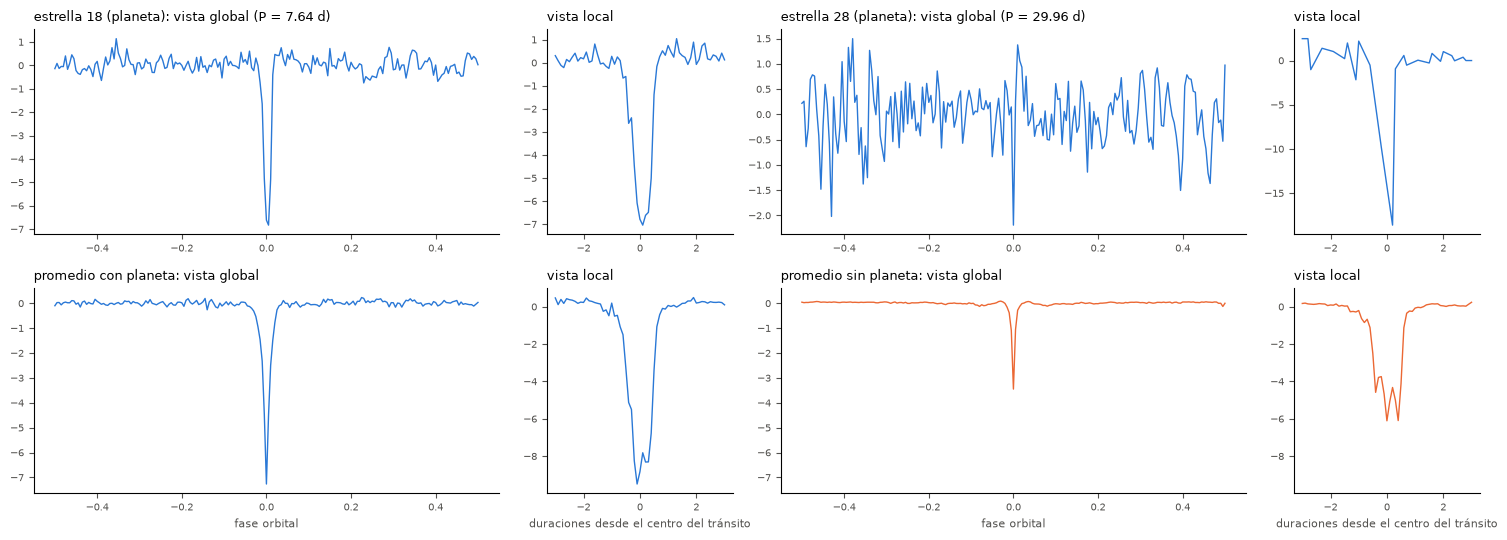

In [2]:
fig, axes = plt.subplots(2, 4, figsize=(15, 5.5), gridspec_kw=dict(width_ratios=[3, 1.2, 3, 1.2]))
fase_g = np.linspace(-0.5, 0.5, N_GLOBAL)
fase_l = np.linspace(-3, 3, N_LOCAL)   # ±LOCAL_DURACIONES duraciones
ejemplos = {18: 'estrella 18 (planeta)', 28: 'estrella 28 (planeta)'}
for k, (idx, tit) in enumerate(ejemplos.items()):
    ax_g, ax_l = axes[0, 2 * k], axes[0, 2 * k + 1]
    ax_g.plot(fase_g, V[idx, :N_GLOBAL], color=ACENTO, lw=1)
    ax_l.plot(fase_l, V[idx, N_GLOBAL:], color=ACENTO, lw=1)
    ax_g.set_title(f'{tit}: vista global (P = {d["bls"][idx, 0]:.2f} d)', fontsize=9, loc='left')
    ax_l.set_title('vista local', fontsize=9, loc='left')
for k, (lab, tit, col) in enumerate([(1, 'promedio con planeta', ACENTO), (0, 'promedio sin planeta', NEGATIVO)]):
    ax_g, ax_l = axes[1, 2 * k], axes[1, 2 * k + 1]
    ax_g.plot(fase_g, V[y == lab, :N_GLOBAL].mean(axis=0), color=col, lw=1)
    ax_l.plot(fase_l, V[y == lab, N_GLOBAL:].mean(axis=0), color=col, lw=1)
    ax_g.set_title(f'{tit}: vista global', fontsize=9, loc='left')
    ax_l.set_title('vista local', fontsize=9, loc='left')
# misma escala vertical en los promedios con y sin planeta, para poder compararlos
for a, b in [(axes[1, 0], axes[1, 2]), (axes[1, 1], axes[1, 3])]:
    lo = min(a.get_ylim()[0], b.get_ylim()[0]); hi = max(a.get_ylim()[1], b.get_ylim()[1])
    a.set_ylim(lo, hi); b.set_ylim(lo, hi)
for ax in axes.ravel():
    ax.tick_params(labelsize=7, colors=TEXTO)
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
for ax in axes[1, ::2]:
    ax.set_xlabel('fase orbital', fontsize=8, color=TEXTO)
for ax in axes[1, 1::2]:
    ax.set_xlabel('duraciones desde el centro del tránsito', fontsize=8, color=TEXTO)
plt.tight_layout()
plt.savefig('../results/10_vistas_plegadas.png', dpi=150, bbox_inches='tight')
plt.show()

## Validación cruzada (5×5)

In [3]:
ENTRADAS = {'plegada': V, '18+plegada': np.c_[V, X18]}
CONFIGS = {
    'rf_plegada':       ('Random Forest, vistas plegadas', 'plegada', make_random_forest),
    'mlp_plegada':      ('Red feedforward, vistas plegadas', 'plegada', lambda: FeedforwardClassifier()),
    'mlp_plegada_flip': ('Red feedforward, vistas plegadas + inversión', 'plegada',
                         lambda: FeedforwardClassifier(flip_views=True)),
    'rf_18_plegada':    ('Random Forest, 18 features + vistas', '18+plegada', make_random_forest),
    'mlp_18_plegada':   ('Red feedforward, 18 features + vistas', '18+plegada', lambda: FeedforwardClassifier()),
}
for nombre, (_, entrada, make) in CONFIGS.items():
    if (OUT / f'{nombre}.csv').exists():
        continue
    folds, oof = repeated_cv(make, ENTRADAS[entrada], y, n_splits=5, n_repeats=5)
    folds.to_csv(OUT / f'{nombre}.csv', index=False)
    np.save(OUT / f'{nombre}_oof.npy', oof.astype(np.float32))
    print(nombre, 'PR-AUC %.3f' % summarize_cv(folds).loc['pr_auc', 'mean'])

In [4]:
ref = pd.read_csv(ABL / 'rf_base.csv')
todas = {'rf_base': ('Random Forest, 18 features (referencia)', ABL)} | {k: (v[0], OUT) for k, v in CONFIGS.items()}
filas = []
for clave, (etiqueta, carpeta) in todas.items():
    folds, oof = pd.read_csv(carpeta / f'{clave}.csv'), np.load(carpeta / f'{clave}_oof.npy')
    s = summarize_cv(folds)
    m = compute_metrics(np.tile(y, len(oof)), oof.ravel(), choose_threshold(y, oof))
    fila = {'modelo': etiqueta, 'pr_auc': s.loc['pr_auc', 'mean'], 'pr_auc_std': s.loc['pr_auc', 'std'],
            'recall@umbral_cv': m['recall'], 'prec@umbral_cv': m['precision']}
    if clave != 'rf_base':
        r = paired_tests(paired_diff(folds, ref))
        fila.update({'delta vs ref': r['delta'], 'mejora en': f"{(paired_diff(folds, ref) > 0).sum()}/25",
                     'p_t_corregido': r['p_t_corregido'], 'p_wilcoxon': r['p_wilcoxon']})
    filas.append(fila)
tabla = pd.DataFrame(filas)
mask = tabla.p_t_corregido.notna()
tabla.loc[mask, 'p_holm'] = holm(tabla.loc[mask, 'p_t_corregido'])
tabla.loc[mask, 'p_wilcoxon_holm'] = holm(tabla.loc[mask, 'p_wilcoxon'])
tabla.to_csv('../results/10_comparacion.csv', index=False)
tabla.round(3)

,modelo,pr_auc,pr_auc_std,recall@umbral_cv,prec@umbral_cv,delta vs ref,mejora en,p_t_corregido,p_wilcoxon,p_holm,p_wilcoxon_holm
0,"Random Forest, 18 features (referencia)",0.394,0.200,0.324,0.706,NaN,NaN,NaN,NaN,NaN,NaN
1,"Random Forest, vistas plegadas",0.206,0.111,0.238,0.314,-0.189,4/25,0.083,0.000,0.166,0.000
2,"Red feedforward, vistas plegadas",0.108,0.097,0.092,0.288,-0.286,1/25,0.012,0.000,0.059,0.000
3,"Red feedforward, vistas plegadas + inversión",0.131,0.104,0.114,0.323,-0.264,1/25,0.023,0.000,0.090,0.000
4,"Random Forest, 18 features + vistas",0.319,0.129,0.303,0.566,-0.076,6/25,0.285,0.003,0.285,0.003
5,"Red feedforward, 18 features + vistas",0.219,0.104,0.249,0.271,-0.176,1/25,0.040,0.000,0.119,0.000


## Conclusiones

**La vista plegada no mejora los resultados: todas las variantes quedan por debajo del Random Forest con las 18
features (0,39).** El RF sobre las vistas obtiene 0,21; la red feedforward, 0,11 (0,13 con inversión temporal); y
agregar las vistas a las 18 features también empeora (RF 0,32, red 0,22). Las diferencias negativas son consistentes
(las variantes mejoran en a lo sumo 6 de 25 folds) y significativas con Wilcoxon + Holm; con el t-test corregido +
Holm, ninguna lo es. Se reportan todas las variantes probadas.

Por qué no funcionó:
1. **El plegado depende del período del BLS.** Ayuda cuando el período es correcto (estrella 18), pero los planetas
   que se escapan son justamente aquellos en que el BLS eligió un período espurio (notebook 08): plegar en un
   período equivocado no apila sus tránsitos. El cuello de botella sigue estando en la búsqueda del período.
2. **El BLS centra todas las vistas en una caída, también en las estrellas sin planeta.** La vista promedio sin
   planeta tiene una caída central de la mitad de profundidad que la de los planetas. La información que distingue
   (profundidad, forma, SNR) es la que ya resumen las 6 features BLS, en 6 números en vez de 262.
3. **Demasiadas entradas para tan pocos positivos.** 262 valores con 37 positivos favorecen el sobreajuste de la red,
   y al juntarlas con las 18 features, el RF elige con menos frecuencia las features útiles al sortear columnas
   en cada nodo.

Diferencia con Shallue y Vanderburg (2018): su trabajo pliega en el período de **candidatos ya detectados** por el
pipeline de Kepler (catálogo DR24, con miles de ejemplos etiquetados) y clasifica si la señal es un planeta. Aquí el
período sale de nuestro propio BLS sobre una curva corta (~67 días), con 37 positivos. Para que el plegado sirva,
primero haría falta una búsqueda de período más confiable: por ejemplo, exigir varias repeticiones, lo que ya mostró una
mejora leve en el notebook 07, o considerar los 2–3 mejores períodos del BLS (mejora M2).